# 03 - Augmentation de donnees : le module `vtb.augment`

Ce qu'on apprend ici :
- pourquoi une augmentation est une HYPOTHESE sur l'etiquette, et comment la choisir ;
- les 45 operations du module (geometrie, photometrie, capteur et eclairage industriels,
  occlusion, politiques automatiques, defauts synthetiques) et les 7 presets ;
- verifier que les boites et les masques suivent l'image (et attraper une operation qui les oublie) ;
- MixUp / CutMix, copy-paste de defauts, mosaique ;
- mesurer la vitesse, ecrire sa propre operation ;
- une experience chiffree : le meme petit reseau sur 25 images par classe, avec et sans augmentation,
  teste sur la meme acquisition ET sur une acquisition changee (nouvel eclairage).

Ce notebook est un des deux qui importent `vtb.augment` (c'est son sujet) ; le module est
autonome : le dossier `src/vtb/augment/` se copie seul dans un autre projet.

Prerequis : le socle de la toolbox ; donnees `python tools/get_data/get_neu_cls.py`,
`get_neu_det.py`, `get_magnetic_tile.py`. Duree en mode QUICK sur CPU 2 coeurs : ~4 minutes.

**Dans le fil** : ce notebook approfondit l'etape 6 (Augmenter). MixUp et CutMix se font au niveau du
lot : ils touchent aussi l'etape 7 (Charger par lots).
Le fil des 13 etapes, le meme que dans le cours : `ETAPES.md`, a la racine de la toolbox.

In [1]:
# REGLAGES : tout ce qu'on change pour ses propres donnees est ici.
from pathlib import Path  # Path : represente un chemin de fichier, fonctionne sous Windows comme sous Linux

import torch  # PyTorch : calcul sur des tenseurs (tableaux de nombres, sur CPU ou GPU) et reseaux de neurones

DATA_CLS = Path("data/raw/neu_cls_flat")  # NEU-CLS : un sous-dossier par classe (classification = une seule etiquette par image)
DATA_DET = Path("data/raw/neu_det")  # NEU-DET : IMAGES/*.jpg + ANNOTATIONS/*.xml au format VOC (boites autour des defauts = detection)
DATA_TILE = Path("data/raw/magnetic_tile")  # Magnetic Tile : MT_<type>/Imgs/<nom>.jpg + <nom>.png (masque : defaut marque pixel par pixel)
QUICK = True  # True : experience courte sur CPU ; False : plus d'epoques (passages sur tout le jeu) et de graines, GPU conseille
SEED = 0  # graine du hasard : la meme graine redonne les memes tirages (resultats reproductibles)
# calcule sur la carte graphique (GPU, "cuda") si elle existe, sinon sur le processeur (CPU)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT = Path("outputs/notebooks/03_augmentation")  # dossier ou ce notebook range ses sorties
OUT.mkdir(parents=True, exist_ok=True)  # cree le dossier et ses parents ; exist_ok=True : pas d'erreur s'il existe deja

TRAIN_PER_CLASS = 25  # 25 images d'entrainement par classe : le cas difficile, tres peu d'images
TEST_PER_CLASS = 50 if QUICK else 100  # images de test par classe (jamais vues a l'entrainement) : 50 en mode rapide, 100 sinon
SIZE = 96 if QUICK else 128  # cote en pixels des images de l'experience : plus petit = entrainement plus rapide
EPOCHS = 40 if QUICK else 80  # nombre d'epoques (passages complets sur les images d'entrainement) par entrainement
SEEDS = [0, 1, 2] if QUICK else [0, 1, 2, 3, 4]  # graines testees : on repete l'experience pour mesurer la part du hasard
PRESET = "steel_texture"  # preset = liste toute prete d'augmentations (modifications aleatoires des images) ; celui-ci est teste

In [2]:
import inspect  # inspect : lit la signature d'une fonction (la liste de ses parametres)
import time  # time : chronometre (mesure des durees)
import warnings  # warnings : permet de masquer des avertissements sans importance
import xml.etree.ElementTree as ET  # ElementTree : lit les fichiers XML (format des annotations VOC)

import cv2  # OpenCV : lecture, redimensionnement et filtrage d'images
import numpy as np  # numpy : calcul sur des tableaux de nombres (une image = un tableau)
import pandas as pd  # pandas : tableaux de donnees (DataFrame) faciles a afficher et a regrouper
from IPython.display import display  # display : affiche joliment un tableau dans le notebook
from torchvision import tv_tensors  # tv_tensors : tenseurs "etiquetes" (boites, masque) que torchvision transforme avec l'image
from torchvision.transforms import v2  # v2 : les transformations d'images de torchvision (version 2 : gere aussi boites et masques)
from torchvision.transforms.v2 import functional as F  # F : ces transformations en fonctions simples, parametres choisis a la main

import vtb.augment as A  # A : le module d'augmentation de la toolbox (operations, presets, outils de controle)
from vtb import viz  # viz : fonctions d'affichage de la toolbox (grilles d'images, boites, masques, tableaux)
from vtb.augment.ops import ImageOnly  # ImageOnly : classe de base pour ecrire une operation qui ne change que l'image (section 10)

viz.setup_notebook(dpi=80, fmt="jpeg")  # regle les figures : 80 points par pouce, format jpeg (notebook plus leger)
N_OPS = len(A.OPS)  # nombre d'operations du catalogue, compte avant l'operation maison ajoutee en section 10
# masque un avertissement de torchvision ("passing through") sans consequence ici
warnings.filterwarnings("ignore", message=".*passing through.*")
pd.set_option("display.max_colwidth", 90)  # pandas affiche jusqu'a 90 caracteres par cellule : les resumes restent lisibles
torch.manual_seed(SEED)  # fixe la graine de PyTorch : memes tirages aleatoires a chaque execution


# lit une image en niveaux de gris ; renvoie un tableau numpy 2D (hauteur x largeur), valeurs 0-255
def read_gray(path: Path) -> np.ndarray:
    """Lecture robuste (chemins Windows avec accents) en niveaux de gris 8 bits."""
    # np.fromfile lit les octets (chemins avec accents acceptes), imdecode les decode en image grise 8 bits
    return cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_GRAYSCALE)


# convertit une image numpy en tenseur PyTorch (1, H, W) a valeurs dans [0, 1] et le renvoie
def to_tensor(image: np.ndarray) -> torch.Tensor:
    """uint8 (H, W) -> float (1, H, W) dans [0, 1] : la forme qu'attend vtb.augment."""
    # / 255 ramene les valeurs dans [0, 1] ; [None] ajoute l'axe des canaux en tete : (H, W) -> (1, H, W)
    return torch.from_numpy(image.astype(np.float32) / 255.0)[None]


# construit une etape d'augmentation forcee (s'applique a coup sur) pour bien la voir ; renvoie un dict
def forced(name: str, **params) -> dict:
    """Etape qui s'applique a coup sur (p = 1) pour la montrer."""
    # l'etape : nom de l'operation + ses parametres, le meme format que dans le YAML (fichier de config d'une recette)
    step = {"name": name, **params}
    # si le constructeur de l'operation a un parametre p (probabilite d'etre appliquee)...
    if "p" in inspect.signature(A.OPS[name].builder).parameters:
        step["p"] = 1.0  # ...on le met a 1 : l'operation s'applique a chaque appel
    return step  # renvoie l'etape, prete pour A.build_augmentation

## 1. Une augmentation est une hypothese

Augmenter, c'est affirmer : "l'etiquette ne change pas si l'on fait ceci a l'image". Le modele
apprend alors a ignorer ce changement. Si l'hypothese est fausse, on lui apprend une erreur.

| operation | hypothese | fausse quand |
|---|---|---|
| retournement | le defaut n'a pas de sens gauche / droite | texte, fleche, piece asymetrique en pose fixe |
| rot90 | pas de direction privilegiee | bande laminee (la direction de laminage compte), rayures toujours longitudinales |
| zoom | la taille ne decide pas de la classe | classe definie par une taille (trou > 2 mm = rebut) |
| eclairage, exposition | le defaut ne se definit pas par sa luminosite | "tache claire" vs "tache sombre" sont deux classes |
| flou, basse resolution | le defaut reste visible flou | defauts de quelques pixels (piqures) : ils disparaissent |
| trous (dropout) | une partie de l'image suffit | le defaut est petit : on le cache, l'etiquette ment |
| poussieres, taches | les taches ne sont pas des defauts | elles en sont une classe, ou on apprend le "normal" (anomalies) |

Regle pratique : n'augmenter qu'avec des variations qu'on VERRA en production (autre eclairage,
autre camera, autre position), et toujours REGARDER le resultat avant d'entrainer.

In [3]:
catalog = A.augmentation_catalog()  # tableau pandas de toutes les operations : nom, famille, taches permises, resume
print(catalog.groupby("family").size().rename("operations").to_string())  # compte les operations par famille et affiche le resultat
catalog[["name", "family", "tasks", "summary"]]  # derniere ligne de la cellule : le notebook affiche ces 4 colonnes du catalogue

family
capteur        15
geometrie      13
occlusion       3
photometrie     9
politique       4
synthese        1


,name,family,tasks,summary
0,hflip,geometrie,"classification, detection, segmentation",retournement gauche-droite
1,vflip,geometrie,"classification, detection, segmentation",retournement haut-bas
2,rot90,geometrie,"classification, detection, segmentation","rotation de 90, 180 ou 270 degres (pas pour une bande orientee)"
3,rotate,geometrie,"classification, detection, segmentation","rotation quelconque dans [-degrees, degrees] (coins noirs)"
4,affine,geometrie,"classification, detection, segmentation",rotation + translation + echelle + cisaillement
5,random_resized_crop,geometrie,"classification, detection, segmentation",recadrage aleatoire puis taille fixe (peut couper un defaut)
6,perspective,geometrie,"classification, detection, segmentation",deformation de perspective (camera inclinee)
7,elastic,geometrie,"classification, detection, segmentation","deformation elastique locale (matiere souple, lent)"
8,zoom,geometrie,"classification, detection, segmentation","zoom avant / arriere, taille de sortie inchangee"
9,translate,geometrie,"classification, detection, segmentation",decalage horizontal et vertical


In [4]:
A.presets_table()  # tableau des 7 presets : operations incluses et raisonnement

,preset,steps,summary
0,light,"hflip, vflip, brightness_contrast, gamma","Variations faibles et sures (retournements, un peu de lumiere) : le point de depart qu..."
1,medium,"hflip, vflip, brightness_contrast, gamma, affine, illumination_gradient, gaussian_nois...","Le reglage par defaut d'un petit jeu industriel : light + petite affine, bruit, flou e..."
2,strong,"hflip, vflip, rot90, brightness_contrast, gamma, affine, perspective, illumination_gra...","Pour un tres petit jeu ou un modele qui sur-apprend vite : rot90, perspective, exposit..."
3,steel_strip,"hflip, vflip, affine, illumination_gradient, exposure, line_stripes, motion_blur, gaus...","Bande d'acier qui defile VERTICALEMENT sous une camera lineaire : retournements oui, r..."
4,steel_texture,"hflip, vflip, rot90, affine, brightness_contrast, gamma, illumination_gradient, gaussi...","Vignettes de surface texturee sans direction privilegiee (type NEU-CLS, tuiles) : les ..."
5,metal_part,"affine, exposure, specular, vignetting, gaussian_noise, defocus_blur","Piece usinee en position fixe (bridage, robot) : PAS de retournement (une piece en mir..."
6,anomaly_normals,"exposure, gamma, gaussian_noise, translate","Pour apprendre le NORMAL (auto-encodeur, STFPM...) : seulement la variabilite d'acquis..."


## 2. Tour des familles sur une image d'acier

Chaque operation est forcee (p = 1) sur la meme vignette NEU-CLS (rayures, 200 x 200, gris).
Les geometriques deplacent les pixels ; les photometriques et "capteur" changent les valeurs ;
l'occlusion cache une partie de l'image.

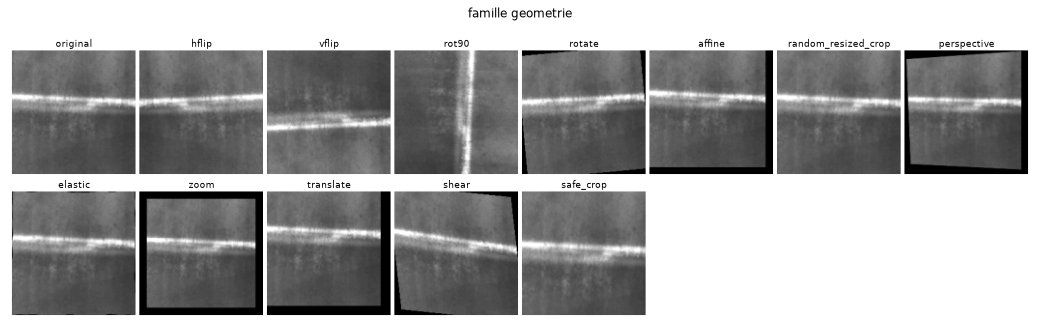

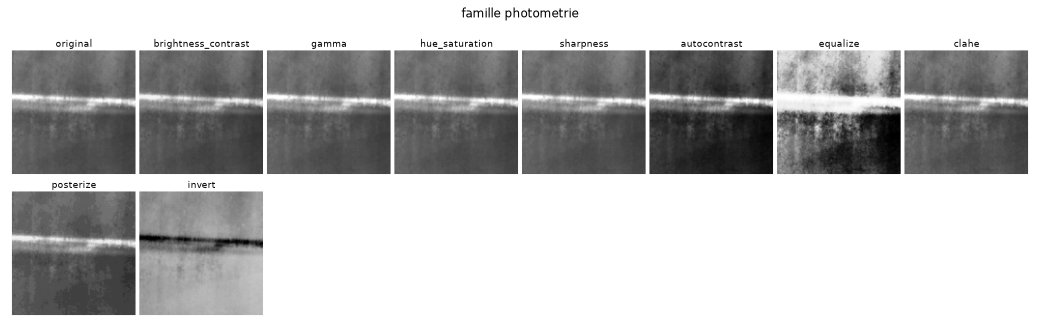

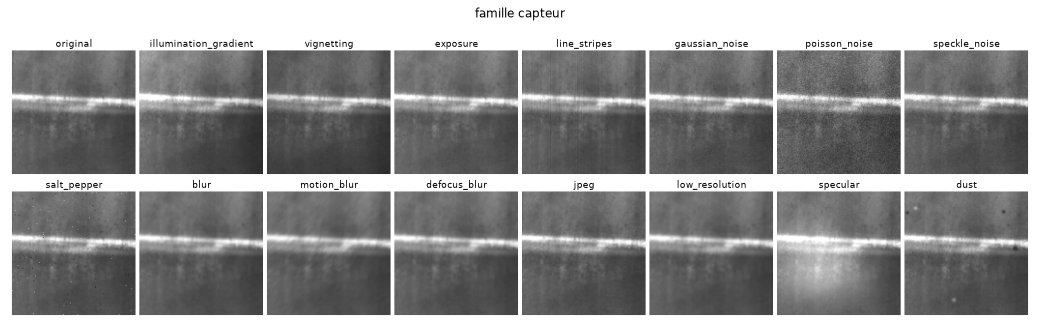

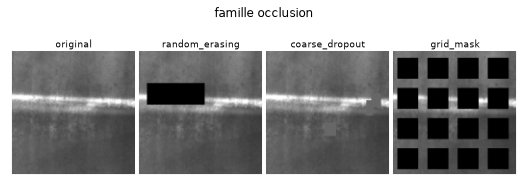

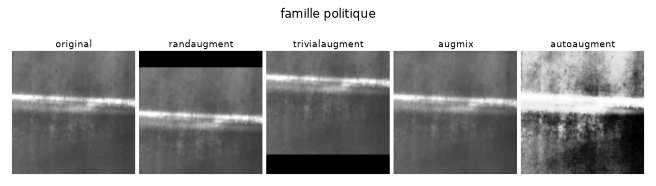

In [5]:
classes = sorted(p.name for p in DATA_CLS.iterdir() if p.is_dir())  # noms des classes = noms des sous-dossiers, tries pour un ordre stable
sample_path = sorted((DATA_CLS / "scratches").glob("*.bmp"))[3]  # 4e image (indice 3) de la classe "rayures", prise comme exemple
x = to_tensor(read_gray(sample_path))  # l'image d'exemple en tenseur (1, 200, 200) dans [0, 1]
# pour chaque famille d'operations : une grille de resultats
for family in ["geometrie", "photometrie", "capteur", "occlusion", "politique"]:
    names = catalog.loc[catalog["family"] == family, "name"].tolist()  # noms des operations de cette famille, lus dans le catalogue
    images, titles = [x], ["original"]  # la grille commence par l'image d'origine, pour comparer
    for name in names:  # pour chaque operation de la famille
        # etape forcee ; random_resized_crop recoit en plus sa taille de sortie (200 x 200)
        step = forced(name, size=(200, 200)) if name == "random_resized_crop" else forced(name)
        if name == "scale_jitter":  # scale_jitter change la taille de l'image...
            continue  # ...on la saute : elle est reservee a la detection
        torch.manual_seed(SEED)  # meme graine avant chaque operation : tirages comparables d'une operation a l'autre
        # construit une augmentation d'une seule etape et l'applique a l'image
        images.append(A.build_augmentation([step], "classification")(x))
        titles.append(name)  # titre de la vignette = nom de l'operation
    # affiche la famille en grille de 8 colonnes (vignettes reduites a 128 px au plus)
    viz.grid(images, titles, ncols=8, size=1.6, max_side=128, suptitle=f"famille {family}")

Ce qu'on regarde : `rotate` et `perspective` creent des coins noirs (a eviter sur une texture :
preferer `rot90`, `zoom`, `translate`) ; `equalize` et `autocontrast` changent fortement
l'aspect ; `invert` n'a de sens que si la polarite varie. Les operations "capteur" sont celles
qu'on rencontre vraiment en ligne : gradient d'eclairage, exposition, stries d'une camera
lineaire, flou de defilement, bruit de photons, compression.

## 3. Les presets compares

Un preset est une liste d'operations avec son raisonnement (`A.presets_table()`). Dans le YAML
d'une recette : `augment: [{name: preset, preset: steel_strip}]`, eventuellement
`exclude: [rot90]` et des operations ajoutees apres.

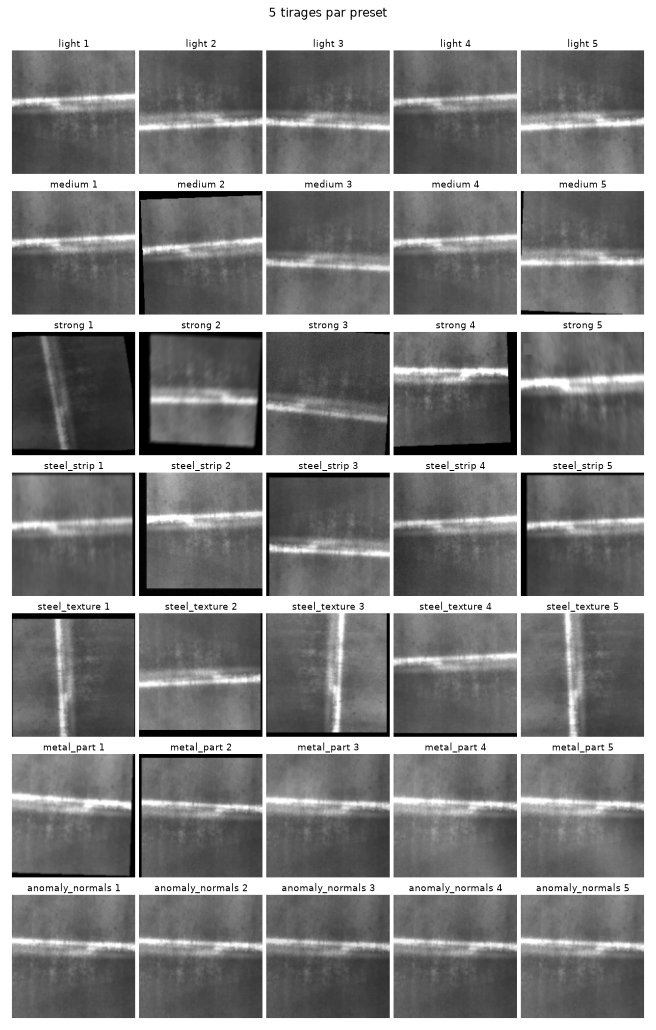

In [6]:
cells, titles = [], []  # vignettes et titres de la future grille
for preset in A.PRESETS:  # pour chaque preset disponible
    # augmentation complete du preset (un Compose : les etapes s'enchainent)
    aug = A.build_augmentation([{"name": "preset", "preset": preset}], "classification")
    torch.manual_seed(SEED)  # meme graine pour chaque preset : comparaison equitable
    for k in range(5):  # 5 tirages : chaque appel tire de nouveaux parametres aleatoires
        cells.append(aug(x))  # applique le preset a l'image et garde le resultat
        titles.append(f"{preset} {k + 1}")  # titre : nom du preset et numero du tirage
viz.grid(cells, titles, ncols=5, size=1.6, max_side=128, suptitle="5 tirages par preset")  # une ligne de 5 vignettes par preset

In [7]:
# detail du preset steel_strip en detection : chaque operation, sa probabilite, ses parametres
A.describe([{"name": "preset", "preset": "steel_strip"}], "detection")

,step,transform,p,params
0,1,RandomHorizontalFlip,0.5,{}
1,2,RandomVerticalFlip,0.5,{}
2,3,RandomAffine,0.5,"{'degrees': ['-0.0', '0.0'], 'translate': ('0.05', '0.05'), 'scale': ('0.95', '1.05'),..."
3,4,IlluminationGradient,0.5,"{'strength': ('0.05', '0.3'), 'mode': 'linear', 'angle': ('-10.0', '10.0')}"
4,5,Exposure,0.5,"{'gain': ('0.8', '1.25'), 'offset': ('-0.03', '0.03')}"
5,6,LineStripes,0.3,"{'strength': ('0.005', '0.03'), 'axis': 'columns'}"
6,7,MotionBlur,0.2,"{'length': ('3.0', '7.0'), 'angle': ('90.0', '90.0')}"
7,8,RandomGaussianNoise,0.3,"{'sigma': ('0.005', '0.02')}"
8,9,Clamp01,1.0,{}
9,10,ClampBoundingBoxes,1.0,{'clamping_mode': 'auto'}


## 4. Les boites et les masques suivent l'image

Torchvision v2 transforme ensemble l'image, les `tv_tensors.BoundingBoxes` et les
`tv_tensors.Mask` passes dans le meme appel : `aug(image, boxes)` en detection,
`aug(image, mask)` en segmentation. Les operations photometriques ne touchent que l'image.
En detection, une boite sortie de l'image devient vide et `A.sanitize_boxes` la retire AVEC son
etiquette.

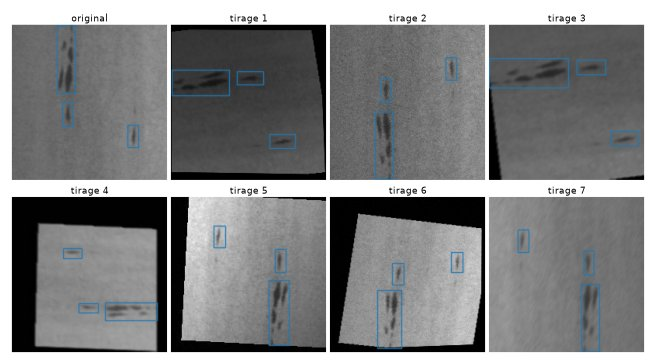

In [8]:
# les 6 classes de defauts de NEU-DET ; position dans la liste = indice de classe
DET_CLASSES = ["crazing", "inclusion", "patches", "pitted_surface", "rolled-in_scale", "scratches"]


# lit un fichier VOC (XML) ; renvoie les boites (N, 4) en xyxy (coins haut-gauche et bas-droite) et les classes (N,)
def read_voc(xml_path: Path) -> tuple[np.ndarray, np.ndarray]:
    """Boites (N, 4) xyxy et indices de classe (N,) d'un fichier VOC."""
    root = ET.parse(xml_path).getroot()  # lit le fichier XML et prend sa balise racine
    boxes, labels = [], []  # listes a remplir : une boite et une classe par objet
    for obj in root.iter("object"):  # pour chaque objet (defaut) annote dans le fichier
        bb = obj.find("bndbox")  # la balise qui contient les coordonnees de la boite
        # lit xmin, ymin, xmax, ymax en nombres decimaux : la boite au format xyxy
        boxes.append([float(bb.find(k).text) for k in ("xmin", "ymin", "xmax", "ymax")])
        labels.append(DET_CLASSES.index(obj.find("name").text))  # nom de classe -> indice (sa position dans DET_CLASSES)
    # tableaux numpy ; reshape(-1, 4) garde la forme (0, 4) si l'image n'a aucun objet
    return np.array(boxes, np.float32).reshape(-1, 4), np.array(labels, np.int64)


det_name = "inclusion_10"  # image d'exemple de NEU-DET (classe inclusion)
det_image = to_tensor(read_gray(DATA_DET / "IMAGES" / f"{det_name}.jpg"))  # l'image en tenseur (1, H, W) dans [0, 1]
det_boxes_np, det_labels = read_voc(DATA_DET / "ANNOTATIONS" / f"{det_name}.xml")  # ses boites et classes, lues dans le XML de meme nom
# BoundingBoxes : torchvision saura deplacer ces boites avec l'image (format xyxy, taille de l'image hauteur x largeur)
det_boxes = tv_tensors.BoundingBoxes(torch.from_numpy(det_boxes_np), format="XYXY", canvas_size=tuple(det_image.shape[-2:]))
# augmentation du preset "strong" en mode detection : les boites suivent l'image
det_aug = A.build_augmentation([{"name": "preset", "preset": "strong"}], "detection")
# 7 tirages avec les boites dessinees : on verifie a l'oeil qu'elles restent sur les defauts
viz.show_augmentations(det_image, det_aug, target=det_boxes, n=7, ncols=4, max_side=200)

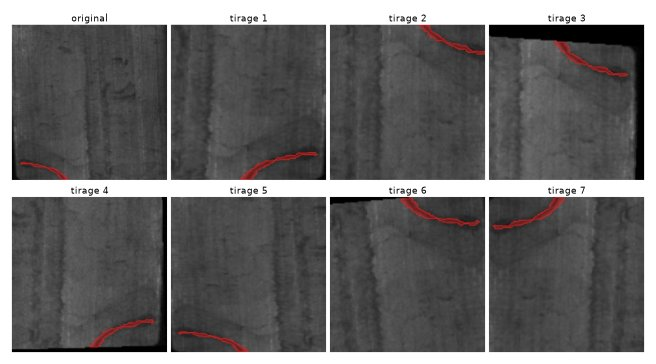

In [9]:
# dossier Magnetic Tile -> indice de classe ecrit dans le masque (0 est reserve au fond)
TILE_CLASSES = {"MT_Blowhole": 1, "MT_Break": 2, "MT_Crack": 3, "MT_Fray": 4, "MT_Uneven": 5}
TILE_NAMES = ["background", "blowhole", "break", "crack", "fray", "uneven"]  # nom de chaque indice de classe du masque, de 0 (fond) a 5
TILE = 256  # cote en pixels des tuiles apres redimensionnement


# lit une tuile et son masque, les ramene a 256 x 256 ; renvoie (image en tenseur, masque d'indices de classe)
def read_tile(image_path: Path, label: int) -> tuple[torch.Tensor, torch.Tensor]:
    """Tuile ramenee a 256 x 256 ; masque binarise (le PNG fourni a des niveaux intermediaires) -> indice de classe."""
    # lit l'image et la redimensionne ; INTER_AREA : moyenne des pixels, le bon choix pour reduire
    image = cv2.resize(read_gray(image_path), (TILE, TILE), interpolation=cv2.INTER_AREA)
    mask_path = image_path.with_suffix(".png")  # le masque porte le meme nom que l'image, en .png
    # lit le masque s'il existe, sinon masque tout a 0 (tuile sans defaut)
    raw = read_gray(mask_path) if mask_path.exists() else np.zeros_like(image)
    # binarise (> 127 = defaut), redimensionne en INTER_NEAREST (aucune valeur intermediaire), puis 1 -> indice de classe
    mask = cv2.resize((raw > 127).astype(np.uint8), (TILE, TILE), interpolation=cv2.INTER_NEAREST).astype(np.int64) * label
    return to_tensor(image), torch.from_numpy(mask)  # image en tenseur decimal, masque en tenseur d'entiers (int64)


crack_path = sorted((DATA_TILE / "MT_Crack" / "Imgs").glob("*.jpg"))[4]  # 5e tuile de la classe fissure (crack), prise comme exemple
tile_image, tile_mask = read_tile(crack_path, TILE_CLASSES["MT_Crack"])  # la tuile et son masque (pixels de fissure = 3)
# preset "medium" + un safe_crop force (garde 30 a 60 % de la surface), en mode segmentation
seg_aug = A.build_augmentation([{"name": "preset", "preset": "medium"}, forced("safe_crop", area=[0.3, 0.6])], "segmentation")
# 7 tirages avec le masque superpose (Mask : dit a torchvision que c'est un masque) : il doit suivre la fissure
viz.show_augmentations(tile_image, seg_aug, target=tv_tensors.Mask(tile_mask), n=7, ncols=4, max_side=200)

`safe_crop` recadre en gardant TOUS les objets (l'union des boites, ou du masque) puis revient a
la taille d'origine : contrairement a `random_resized_crop`, il ne coupe jamais un defaut.

## 5. Controler l'alignement, automatiquement

`A.check_alignment(aug)` passe une image test asymetrique (rectangle, L, disque) avec ses boites
et son masque dans l'augmentation, 20 fois, et verifie que la zone claire de l'image, le masque
et les boites restent superposes. C'est le test a faire sur toute operation ecrite a la main.

In [10]:
rows = []  # une ligne de resultat par couple (preset, tache)
for preset in A.PRESETS:  # pour chaque preset
    for task in ("detection", "segmentation"):  # teste en detection (boites) puis en segmentation (masque)
        # 20 tirages sur une image test ; IoU = surface commune / surface totale de 2 zones (1 = superposition parfaite)
        result = A.check_alignment([{"name": "preset", "preset": preset}], task, trials=20, seed=SEED)
        # ajoute une ligne : verdict, taux de tirages reussis, IoU medianes du masque et des boites
        # (la ligne suivante garde sa mise en forme grace au commentaire "fmt: skip" lu par ruff)
        rows.append({"preset": preset, "task": task, "ok": result["ok"], "pass_rate": result["pass_rate"],
                     "median_mask_iou": round(result["median_mask_iou"], 3), "median_box_iou": round(result["median_box_iou"], 3)})  # fmt: skip
alignment = pd.DataFrame(rows)  # assemble les lignes en un tableau
display(alignment)  # affiche le tableau : tous les presets doivent etre ok

,preset,task,ok,pass_rate,median_mask_iou,median_box_iou
0,light,detection,True,1.0,1.000,1.000
1,light,segmentation,True,1.0,1.000,1.000
2,medium,detection,True,1.0,1.000,1.000
3,medium,segmentation,True,1.0,1.000,1.000
4,strong,detection,True,1.0,0.994,0.882
5,strong,segmentation,True,1.0,0.994,0.882
6,steel_strip,detection,True,1.0,1.000,1.000
7,steel_strip,segmentation,True,1.0,1.000,1.000
8,steel_texture,detection,True,1.0,1.000,0.969
9,steel_texture,segmentation,True,1.0,1.000,0.969


In [11]:
class FlipImageOnly(v2.Transform):  # exemple FAUX expres : retourne l'image mais oublie de retourner boites et masque
    """Erreur classique : on retourne l'image a la main (inpt.flip) et on oublie les cibles."""

    def transform(self, inpt, params):  # appelee par torchvision pour chaque entree (image, boites, masque) ; renvoie l'entree transformee
        # ne retourne que les tenseurs decimaux (l'image) : boites et masque restent en place, donc desalignes
        return inpt.flip(-1) if isinstance(inpt, torch.Tensor) and inpt.is_floating_point() else inpt


bad = A.check_alignment(FlipImageOnly(), trials=5)  # controle de la version fausse : doit echouer
good = A.check_alignment(v2.RandomHorizontalFlip(1.0), trials=5)  # controle du retournement de torchvision (p = 1) : doit reussir
# verdict et IoU mediane du masque (faible quand l'image et le masque sont desalignes)
print(f"flip ecrit a la main : ok={bad['ok']} (IoU masque median {bad['median_mask_iou']:.2f})")
# meme affichage pour la version torchvision (IoU proche de 1)
print(f"flip torchvision     : ok={good['ok']} (IoU masque median {good['median_mask_iou']:.2f})")

flip ecrit a la main : ok=False (IoU masque median 0.28)
flip torchvision     : ok=True (IoU masque median 1.00)


## 6. MixUp et CutMix (classification, au niveau du lot ; etapes 6 et 7)

MixUp melange deux images et leurs etiquettes (0,7 x A + 0,3 x B -> etiquette 70 / 30) ; CutMix
colle un rectangle de B dans A (etiquette au prorata de la surface). Ils se branchent comme
`collate_fn` du DataLoader d'entrainement ; CrossEntropyLoss accepte les etiquettes douces.
A n'utiliser ni en validation ni en test.

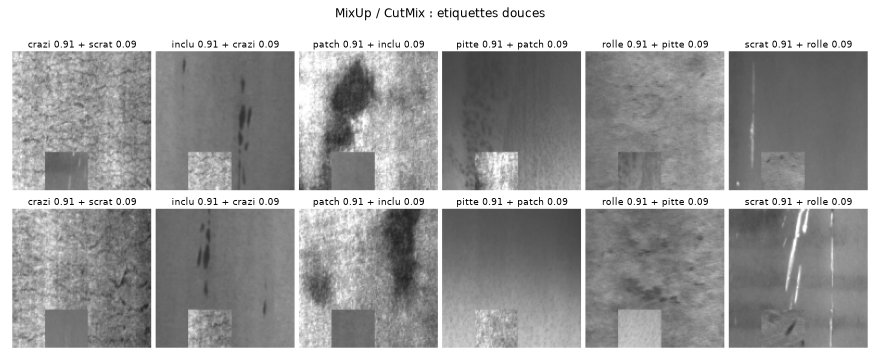

In [12]:
# DataLoader : fournit les donnees par lots (batch = paquet d'images traitees ensemble) ; TensorDataset : jeu deja en memoire
from torch.utils.data import DataLoader, TensorDataset

# 2 images par classe : la 1re de chaque classe, puis la 2e (12 chemins)
paths = [sorted((DATA_CLS / c).glob("*.bmp"))[0] for c in classes] + [sorted((DATA_CLS / c).glob("*.bmp"))[1] for c in classes]
batch_x = torch.stack([to_tensor(read_gray(p)) for p in paths])  # empile les 12 images en un seul tenseur (12, 1, 200, 200)
# etiquettes : indice de classe 0 a 5, deux fois de suite (meme ordre que paths)
batch_y = torch.tensor([i % len(classes) for i in range(len(paths))])
# un seul lot de 12 ; collate_fn (fonction qui assemble le lot) y applique MixUp ou CutMix a coup sur (p = 1)
loader = DataLoader(TensorDataset(batch_x, batch_y), batch_size=len(paths), collate_fn=A.batch_augmentation(len(classes), p=1.0))
torch.manual_seed(SEED)  # graine fixe : memes melanges a chaque execution
mixed_x, mixed_y = next(iter(loader))  # prend le premier (et seul) lot : images melangees + etiquettes douces (une proportion par classe)


def soft_title(row: torch.Tensor) -> str:  # fabrique un titre a partir d'une etiquette douce : les 2 classes principales et leur part
    top = torch.topk(row, 2)  # les 2 plus grandes proportions et leurs indices de classe
    # texte "classe proportion" (5 premieres lettres du nom) pour chaque part superieure a 1 %
    parts = [f"{classes[i][:5]} {v:.2f}" for v, i in zip(top.values.tolist(), top.indices.tolist()) if v > 0.01]
    return " + ".join(parts)  # assemble les morceaux, par exemple "scrat 0.70 + patch 0.30"


# affiche les 12 images melangees avec leur etiquette douce en titre
viz.grid(list(mixed_x), [soft_title(r) for r in mixed_y], ncols=6, size=1.8, max_side=128, suptitle="MixUp / CutMix : etiquettes douces")

## 7. Copy-paste de defauts

Le remede direct au manque de defauts : on decoupe les defauts annotes (masque ou boite) dans
une banque, et on les colle sur d'autres images en mettant a jour masque, boites et etiquettes.
Le bord est adouci et la luminosite accordee au fond d'accueil (sinon le modele apprend a
reconnaitre le collage). A appeler dans `__getitem__`, avant le Compose.

banque : 21 defauts ; par classe : {'blowhole': 6, 'break': 7, 'crack': 8}


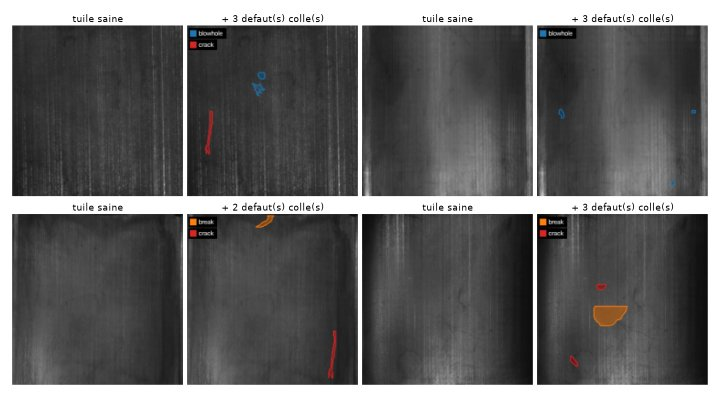

In [13]:
bank_images, bank_masks = [], []  # images et masques d'ou seront decoupes les defauts
for folder in ["MT_Blowhole", "MT_Crack", "MT_Break"]:  # 3 types de defauts : soufflure, fissure, cassure
    for path in sorted((DATA_TILE / folder / "Imgs").glob("*.jpg"))[:6]:  # les 6 premieres tuiles de chaque type
        image, mask = read_tile(path, TILE_CLASSES[folder])  # tuile + masque dont les pixels de defaut valent l'indice de la classe
        bank_images.append(image)  # garde l'image
        bank_masks.append(mask)  # garde son masque (meme position dans la liste)
# banque : chaque defaut (zone d'un seul tenant du masque) decoupe en vignette ; ceux de moins de 20 pixels sont ignores
bank = A.DefectBank.from_masks(bank_images, bank_masks, min_area=20)
# taille de la banque et nombre de defauts par classe (indices traduits en noms)
print(f"banque : {len(bank)} defauts ; par classe : { {TILE_NAMES[k]: v for k, v in sorted(bank.classes().items())} }")

paste = A.CopyPaste(bank, p=1.0, count=(1, 3))  # operation copy-paste : colle a coup sur (p = 1) de 1 a 3 defauts pris dans la banque
# 4 tuiles saines (MT_Free = sans defaut) qui recevront les collages
free_paths = sorted((DATA_TILE / "MT_Free" / "Imgs").glob("*.jpg"))[:4]
cells, titles = [], []  # vignettes et titres de la grille
torch.manual_seed(SEED)  # graine fixe : memes collages a chaque execution
for path in free_paths:  # pour chaque tuile saine
    image, empty = read_tile(path, 0)  # la tuile et son masque vide (tout a 0 = fond)
    out = paste(image, mask=empty)  # colle des defauts : renvoie un dict avec image, masque et etiquettes mis a jour
    # la tuile d'origine, puis le resultat avec le masque colorie par classe
    cells += [image, viz.overlay_mask(out["image"], out["mask"], class_names=TILE_NAMES)]
    titles += ["tuile saine", f"+ {len(out['labels'])} defaut(s) colle(s)"]  # titres : avant, et nombre de defauts colles
viz.grid(cells, titles, ncols=4, size=2.2, max_side=200)  # grille de 4 colonnes : 2 paires avant / apres par ligne

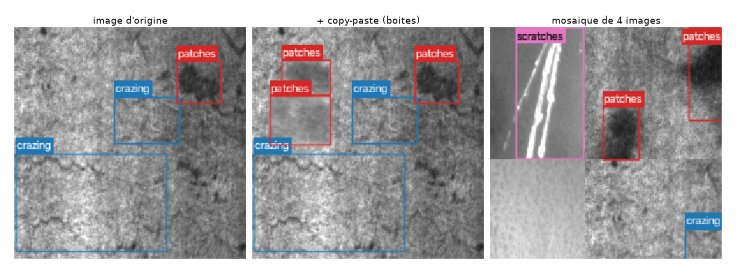

In [14]:
# Detection : banque de boites NEU-DET, collage sur une autre image, puis mosaique de 4 images.
det_names = ["scratches_5", "patches_12", "pitted_surface_8", "crazing_20"]  # 4 images NEU-DET de classes differentes
det_samples = []  # un dict (image, boites, etiquettes) par image
for name in det_names:  # pour chaque image choisie
    image = to_tensor(read_gray(DATA_DET / "IMAGES" / f"{name}.jpg"))  # l'image en tenseur
    boxes, labels = read_voc(DATA_DET / "ANNOTATIONS" / f"{name}.xml")  # ses boites et ses classes
    # range le tout ; boites et etiquettes converties en tenseurs PyTorch
    det_samples.append({"image": image, "boxes": torch.from_numpy(boxes), "labels": torch.from_numpy(labels)})
box_bank = A.DefectBank.from_boxes(  # banque de defauts decoupes dans les boites des 2 premieres images :
    [s["image"] for s in det_samples[:2]],  # les 2 images
    [s["boxes"] for s in det_samples[:2]],  # leurs boites
    [s["labels"] for s in det_samples[:2]],  # leurs etiquettes (indices de classe)
)
torch.manual_seed(SEED)  # graine fixe : collage reproductible
# colle exactement 2 defauts sur la 4e image ; ses boites et etiquettes sont completees
pasted = A.copy_paste(det_samples[3]["image"], box_bank, boxes=det_samples[3]["boxes"], labels=det_samples[3]["labels"], count=(2, 2))
mosaic = A.mosaic(det_samples, size=(200, 200))  # mosaique : les 4 images en damier 2 x 2 dans une image 200 x 200, boites recalculees
viz.grid(  # grille de 3 images cote a cote :
    [  # les 3 images, chacune avec ses boites dessinees :
        # l'image d'origine et ses boites
        viz.draw_boxes(det_samples[3]["image"], det_samples[3]["boxes"], labels=det_samples[3]["labels"].tolist(), class_names=DET_CLASSES),
        # apres copy-paste : boites d'origine + boites collees
        viz.draw_boxes(pasted["image"], pasted["boxes"], labels=pasted["labels"].tolist(), class_names=DET_CLASSES),
        # la mosaique et ses boites recalculees
        viz.draw_boxes(mosaic["image"], mosaic["boxes"], labels=mosaic["labels"].tolist(), class_names=DET_CLASSES),
    ],
    ["image d'origine", "+ copy-paste (boites)", "mosaique de 4 images"],  # titres des 3 vignettes
    ncols=3,  # 3 colonnes
    size=3.0,  # taille de chaque vignette (en pouces)
    max_side=300,  # les images sont reduites a 300 px au plus pour l'affichage
)

## 8. Defauts synthetiques (auto-supervision)

`synthetic_defect` ajoute un defaut fabrique (tache de Perlin facon DRAEM, morceau deplace facon
CutPaste, rayure) ET l'ecrit dans le masque : il change la verite terrain, il est donc reserve a
la segmentation (ou a une boucle maison avec `A.synthesize_defect`). Utile pour verifier une
chaine avant d'avoir des defauts reels ; jamais pour mesurer une performance finale.

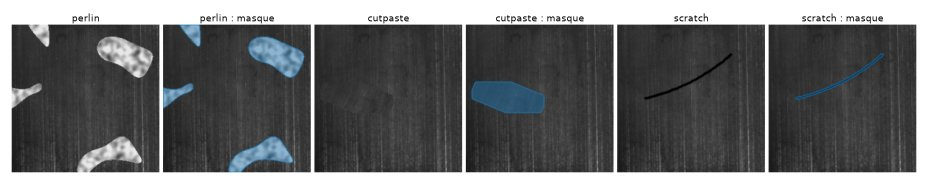

In [15]:
free_image, free_mask = read_tile(free_paths[0], 0)  # une tuile saine et son masque vide
cells, titles = [], []  # vignettes et titres de la grille
# 3 types de defauts fabriques : tache de Perlin (bruit lisse en taches), morceau deplace, rayure
for kind in ["perlin", "cutpaste", "scratch"]:
    torch.manual_seed(SEED + 3)  # graine fixe : meme defaut a chaque execution
    # augmentation qui fabrique a coup sur ce type de defaut (segmentation : le masque est modifie aussi)
    aug = A.build_augmentation([{"name": "synthetic_defect", "kinds": [kind], "p": 1.0}], "segmentation")
    out, out_mask = aug(free_image, tv_tensors.Mask(free_mask))  # renvoie l'image avec le defaut et le masque qui le marque
    cells += [out, viz.overlay_mask(out, out_mask)]  # l'image modifiee, puis le masque superpose
    titles += [kind, f"{kind} : masque"]  # titres : type de defaut, puis son masque
viz.grid(cells, titles, ncols=6, size=1.9, max_side=200)  # 6 colonnes : les 3 defauts et leurs masques sur une ligne

## 9. Vitesse : l'augmentation ne doit pas affamer le GPU

Sur CPU, le chargement des images est souvent le goulot de l'entrainement. `A.benchmark_ops`
mesure chaque operation forcee sur une image de la taille de travail : au-dela de quelques
millisecondes par image, alleger (elastic) ou augmenter `num_workers`.

images / s par preset (1 coeur, 200 x 200) : {'light': 8019, 'medium': 1505, 'strong': 643, 'steel_strip': 1202, 'steel_texture': 1109, 'metal_part': 1411, 'anomaly_normals': 3159}


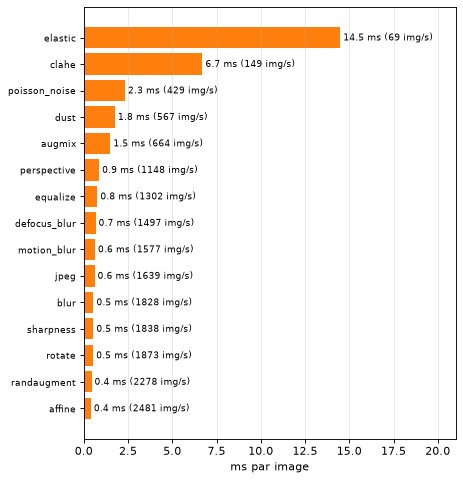

In [16]:
# chronometre chaque operation forcee sur une image 200 x 200 a 1 canal ; tableau du plus lent au plus rapide
speed = A.benchmark_ops(size=(200, 200), channels=1, repeats=10 if QUICK else 50)
# barres des 15 operations les plus lentes (millisecondes par image)
viz.latency_bars(dict(zip(speed["op"].head(15), speed["ms_per_image"].head(15))))
throughput = {}  # images par seconde de chaque preset
for preset in A.PRESETS:  # pour chaque preset
    aug = A.build_augmentation([{"name": "preset", "preset": preset}], "classification")  # construit l'augmentation du preset
    aug(x)  # appel d'echauffement : le premier appel paie des initialisations, on ne le chronometre pas
    start = time.perf_counter()  # depart du chronometre (perf_counter : horloge precise)
    for _ in range(50):  # 50 appels pour une mesure stable
        aug(x)  # applique le preset (resultat jete : seul le temps compte)
    throughput[preset] = round(50 / (time.perf_counter() - start))  # 50 images / temps ecoule = images par seconde, arrondi
print("images / s par preset (1 coeur, 200 x 200) :", throughput)  # debit de chaque preset

## 10. Ecrire sa propre operation

Deux cas :
- **photometrique** (l'image seule change) : heriter de `ImageOnly`, tirer les parametres dans
  `sample` (avec torch : graine et workers respectes), les appliquer dans `apply` ;
- **geometrique** (les cibles doivent suivre) : passer par les fonctions de
  `torchvision.transforms.v2.functional` (`F.rotate`, `F.affine`, `F.resized_crop`...) qui
  transforment aussi boites et masques. Puis TOUJOURS `check_alignment`.

Enregistree dans `A.OPS`, l'operation s'utilise dans le YAML comme les autres.

oil_film depuis le YAML : ['OilFilm', 'Clamp01', 'ClampBoundingBoxes']


SmallTilt aligne : True | OilFilm aligne : True


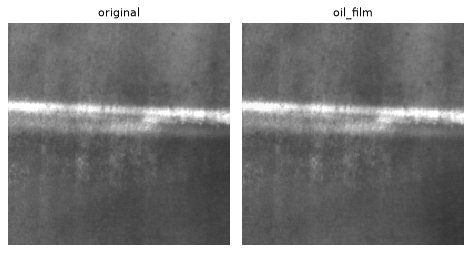

In [17]:
class OilFilm(ImageOnly):  # operation maison photometrique : voile clair et doux ; herite d'ImageOnly car seule l'image change
    """Film d'huile : voile clair, large et doux, a faible contraste (photometrique)."""

    # strength : intervalle d'intensite du voile ; p : probabilite d'appliquer l'operation
    def __init__(self, strength=(0.03, 0.12), p=0.5):
        super().__init__(p)  # la classe parente gere la probabilite p
        self.strength = strength  # garde l'intervalle pour les tirages

    def sample(self, height, width, channels):  # tire les parametres aleatoires d'un appel ; renvoie un dict
        low = torch.rand(1, 1, 4, 4)  # grille 4 x 4 de valeurs au hasard dans [0, 1] : champ grossier, lisse ensuite par interpolation
        # le champ et une intensite tiree uniformement dans l'intervalle strength
        return {"field": low, "strength": float(torch.empty(()).uniform_(*self.strength))}

    def apply(self, image, params):  # applique le voile avec les parametres tires ; renvoie l'image modifiee
        # agrandit la grille 4 x 4 a la taille de l'image (interpolation bicubique : resultat lisse) ; [0] retire l'axe du lot
        field = torch.nn.functional.interpolate(params["field"], size=image.shape[-2:], mode="bicubic", align_corners=False)[0]
        return image + params["strength"] * (field - field.mean())  # ajoute le voile centre (moyenne retiree) multiplie par l'intensite


class SmallTilt(v2.Transform):  # operation maison geometrique : petite rotation ; boites et masque doivent suivre l'image
    """Inclinaison de +/- 3 degres : geometrique, donc F.rotate (boites et masques suivent)."""

    def make_params(self, flat_inputs):  # tire les parametres une fois par appel (les memes pour image, boites et masque) ; renvoie un dict
        return {"angle": float(torch.empty(()).uniform_(-3, 3))}  # angle tire uniformement entre -3 et +3 degres

    def transform(self, inpt, params):  # appelee pour chaque entree avec les memes parametres ; renvoie l'entree transformee
        # si l'entree est des boites, un masque ou l'image (tenseur decimal)...
        if isinstance(inpt, (tv_tensors.BoundingBoxes, tv_tensors.Mask)) or (isinstance(inpt, torch.Tensor) and inpt.is_floating_point()):
            return F.rotate(inpt, params["angle"])  # ...F.rotate la tourne du meme angle (boites et masque compris)
        return inpt  # toute autre entree (les etiquettes par exemple) passe sans changement


# enregistre l'operation dans le catalogue A.OPS sous le nom "oil_film" (OpInfo = fiche de l'operation) :
A.OPS["oil_film"] = A.transforms.OpInfo(
    lambda strength=(0.03, 0.12), p=0.5: OilFilm(strength, p),  # constructeur : parametres du YAML -> objet OilFilm
    "capteur",  # famille de l'operation dans le catalogue
    A.transforms.TASKS,  # taches permises : toutes (classification, detection, segmentation)
    "film d'huile",  # resume d'une ligne affiche par le catalogue
)
A.transforms.BUILDERS["oil_film"] = A.OPS["oil_film"].builder  # et dans la table des constructeurs lue par build_augmentation
# construit l'operation par son nom, comme depuis un YAML, en mode detection
custom = A.build_augmentation([{"name": "oil_film", "p": 1.0}], "detection")
# liste des transformations construites : preuve que le nom est reconnu
print("oil_film depuis le YAML :", A.describe(custom)["transform"].tolist())
print(  # controle d'alignement des deux operations maison :
    "SmallTilt aligne :",  # texte affiche
    A.check_alignment(SmallTilt(), trials=10)["ok"],  # SmallTilt (geometrique, via F.rotate) : doit etre ok
    "| OilFilm aligne :",  # texte affiche
    A.check_alignment(custom, trials=5)["ok"],  # OilFilm (photometrique, l'image seule change) : doit etre ok
)
viz.compare({"original": x, "oil_film": custom(x)}, size=3)  # image d'origine et image avec film d'huile cote a cote

## 11. L'effet chiffre : 25 images par classe, avec et sans augmentation

Le meme petit reseau convolutif (appris de zero), les memes 25 images d'entrainement par classe
(NEU-CLS, 6 classes), plusieurs graines, un nombre d'epoques fixe (pas de selection sur le test).
Trois bras :
- `sans` augmentation ;
- `symetries` : retournements et rot90 seulement (les huit symetries du carre, exactes pour
  une texture sans direction) ;
- `steel_texture` : le preset complet (symetries + echelle, lumiere, gradient, bruit, flou).

Deux tests sur les MEMES images jamais vues :
- `meme acquisition` : les images telles quelles ;
- `acquisition changee` : les memes images vues par une ligne dont l'eclairage a change
  (plus faible et incline, gamma, leger flou et bruit), ce qui arrive en production apres un
  changement de lampe, de camera ou de reglage.

Honnetete : ces changements font partie de ce que le preset simule. L'experience montre le
mecanisme (on devient robuste a ce qu'on a prevu), pas une garantie face a l'imprevu.

train (150, 1, 96, 96), test (300, 1, 96, 96)


9 entrainements en 145 s


meme acquisition        acquisition changee       
                          mean    std                mean    std
arm                                                             
sans                     0.932  0.010               0.431  0.039
symetries                0.929  0.013               0.379  0.033
steel_texture            0.888  0.010               0.567  0.050

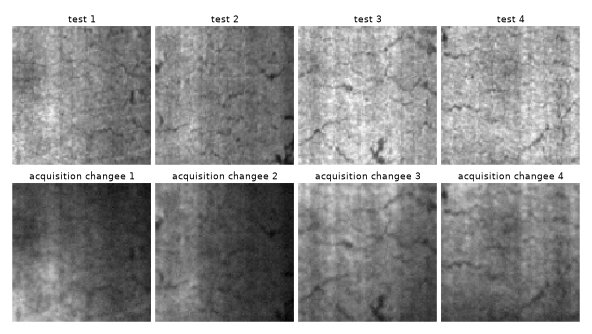

In [18]:
rng = np.random.default_rng(SEED)  # generateur aleatoire numpy avec graine : meme tirage des images a chaque execution
train_items, test_items = [], []  # listes de (chemin, indice de classe) pour l'entrainement et pour le test
for label, name in enumerate(classes):  # pour chaque classe, avec son indice (0, 1, 2...)
    files = sorted((DATA_CLS / name).glob("*.bmp"))  # toutes les images de la classe, triees
    order = rng.permutation(len(files))  # ordre aleatoire des indices d'images
    train_items += [(files[i], label) for i in order[:TRAIN_PER_CLASS]]  # les 25 premieres du melange vont a l'entrainement
    # les suivantes au test : aucune image commune avec l'entrainement
    test_items += [(files[i], label) for i in order[TRAIN_PER_CLASS : TRAIN_PER_CLASS + TEST_PER_CLASS]]


def load_items(items):  # charge une liste de (chemin, classe) ; renvoie images (N, 1, SIZE, SIZE) et etiquettes (N,)
    # lit chaque image et la reduit a SIZE x SIZE
    images = [cv2.resize(read_gray(p), (SIZE, SIZE), interpolation=cv2.INTER_AREA) for p, _ in items]
    # empile en un tenseur d'images et un tenseur d'etiquettes
    return torch.stack([to_tensor(im) for im in images]), torch.tensor([label for _, label in items])


# simule un changement d'eclairage, toujours le meme (graine fixe) ; renvoie les images modifiees
def acquisition_shift(images: torch.Tensor, seed: int = 123) -> torch.Tensor:
    """Nouvel eclairage, fixe et reproductible : gain 0,8, rampe de +/- 30 % (direction tiree par image),
    gamma 1,3, flou de 0,8 pixel, bruit de 2 %."""
    generator = torch.Generator().manual_seed(seed)  # generateur aleatoire propre a cette fonction : meme perturbation a chaque appel
    size = images.shape[-1]  # cote des images (derniere dimension du tenseur)
    # coordonnees y et x de chaque pixel, de -0,5 a +0,5 (0 = centre de l'image)
    yy, xx = torch.meshgrid(torch.linspace(-0.5, 0.5, size), torch.linspace(-0.5, 0.5, size), indexing="ij")
    out = []  # images modifiees
    for image in images:  # pour chaque image (1, H, W) du tenseur
        # direction de la rampe d'eclairage : angle au hasard entre 0 et 2 pi
        theta = float(torch.rand((), generator=generator)) * 2 * np.pi
        # rampe : facteur autour de 1, plus fort d'un cote, plus faible de l'autre, dans la direction theta
        ramp = 1 + 0.6 * (xx * np.cos(theta) + yy * np.sin(theta))
        shifted = (image * 0.8 * ramp).clamp(0, 1) ** 1.3  # gain 0,8 et rampe, borne a [0, 1], puis gamma 1,3 (assombrit les tons moyens)
        # flou gaussien d'ecart-type 0,8 pixel (OpenCV, sur le tableau 2D), puis retour en tenseur (1, H, W)
        shifted = torch.from_numpy(cv2.GaussianBlur(shifted[0].numpy(), (0, 0), 0.8))[None]
        # bruit gaussien de 2 % ajoute, puis borne a [0, 1]
        out.append((shifted + 0.02 * torch.randn(shifted.shape, generator=generator)).clamp(0, 1))
    return torch.stack(out)  # renvoie les images modifiees empilees (N, 1, H, W)


train_x, train_y = load_items(train_items)  # images et etiquettes d'entrainement (6 classes x 25 = 150)
test_x, test_y = load_items(test_items)  # images et etiquettes de test
test_shifted = acquisition_shift(test_x)  # les MEMES images de test, vues avec l'eclairage change
print(f"train {tuple(train_x.shape)}, test {tuple(test_x.shape)}")  # formes des tenseurs : (nombre, canaux, hauteur, largeur)
# 4 images de test puis les memes avec l'acquisition changee (titres en 2e argument), sur 2 lignes de 4
viz.grid([*test_x[:4], *test_shifted[:4]], [f"test {k + 1}" for k in range(4)] + [f"acquisition changee {k + 1}" for k in range(4)],
         ncols=4, size=1.8, max_side=128)  # fmt: skip


class AugmentedSet(torch.utils.data.Dataset):  # jeu de donnees PyTorch : renvoie une image (augmentee si demande) et son etiquette
    def __init__(self, images, labels, augment=None):  # garde les images, les etiquettes et l'augmentation (None = aucune)
        self.images, self.labels, self.augment = images, labels, augment  # stocke les trois dans l'objet

    def __len__(self):  # nombre d'exemples du jeu (le DataLoader en a besoin)
        return len(self.labels)  # = nombre d'etiquettes

    def __getitem__(self, i):  # renvoie l'exemple numero i : (image normalisee, etiquette)
        image = self.images[i]  # l'image i, tenseur (1, H, W)
        if self.augment is not None:  # si une augmentation est fournie...
            image = self.augment(image)  # ...nouveau tirage a chaque lecture : l'image differe a chaque epoque
        # normalisation : valeurs centrees autour de 0 et mises a l'echelle (aide l'apprentissage) ; etiquette en entier
        return (image - 0.5) / 0.25, int(self.labels[i])


# petit reseau convolutif (CNN, reseau de filtres appris) entraine de zero ; renvoie le modele
def small_cnn(num_classes: int) -> torch.nn.Module:
    def block(cin, cout):  # un bloc : cin canaux en entree, cout en sortie ; divise hauteur et largeur par 2
        return torch.nn.Sequential(  # Sequential : les couches ci-dessous, appliquees l'une apres l'autre
            torch.nn.Conv2d(cin, cout, 3, padding=1),  # convolution 3x3 : cout filtres appris ; padding=1 garde la taille
            torch.nn.BatchNorm2d(cout),  # BatchNorm : normalise les sorties de chaque canal (apprentissage plus stable)
            torch.nn.ReLU(),  # ReLU : met les valeurs negatives a 0 (non-linearite)
            torch.nn.MaxPool2d(2),  # MaxPool : garde le maximum de chaque carre 2x2, divise hauteur et largeur par 2
        )

    # 4 blocs (16 -> 64 canaux), moyenne globale (1 valeur par canal), mise a plat, Dropout (eteint 20 % des valeurs
    # au hasard, contre le sur-apprentissage), couche lineaire -> un score par classe (logits)
    return torch.nn.Sequential(block(1, 16), block(16, 32), block(32, 64), block(64, 64), torch.nn.AdaptiveAvgPool2d(1),
                               torch.nn.Flatten(), torch.nn.Dropout(0.2), torch.nn.Linear(64, num_classes))  # fmt: skip


ARMS = {  # les 3 bras de l'experience : nom -> liste d'etapes d'augmentation
    "sans": None,  # aucune augmentation (la reference)
    "symetries": [{"name": "hflip"}, {"name": "vflip"}, {"name": "rot90"}],  # retournements horizontal et vertical, rotations de 90 degres
    PRESET: [{"name": "preset", "preset": PRESET}],  # le preset complet (steel_texture)
}


# taux de bonnes reponses du modele sur des images ; renvoie un nombre entre 0 et 1
def accuracy(model: torch.nn.Module, images: torch.Tensor, labels: torch.Tensor) -> float:
    model.eval()  # mode evaluation : BatchNorm utilise ses statistiques apprises, Dropout est coupe
    with torch.no_grad():  # sans calcul de gradient (direction de correction des poids, inutile pour predire) : plus rapide
        # meme normalisation qu'a l'entrainement ; argmax(1) = classe au plus haut score ; retour sur CPU
        preds = model(((images - 0.5) / 0.25).to(DEVICE)).argmax(1).cpu()
    return float((preds == labels).float().mean())  # part des predictions egales a la vraie classe


def run(arm: str, seed: int) -> dict:  # entraine un modele pour un bras et une graine ; renvoie ses precisions et sa courbe de perte
    torch.manual_seed(seed)  # graine : memes poids de depart et memes tirages pour une graine donnee
    augment = A.build_augmentation(ARMS[arm], "classification") if ARMS[arm] else None  # augmentation du bras (None pour "sans")
    # lots de 16 images melangees a chaque epoque ; generateur avec graine : ordre reproductible
    loader = DataLoader(AugmentedSet(train_x, train_y, augment), batch_size=16, shuffle=True, generator=torch.Generator().manual_seed(seed))
    model = small_cnn(len(classes)).to(DEVICE)  # nouveau reseau (une sortie par classe), place sur le GPU ou le CPU
    # optimiseur AdamW : corrige les poids a partir des gradients ; lr = taille du pas, weight_decay freine les grands poids
    optimizer = torch.optim.AdamW(model.parameters(), lr=3e-3, weight_decay=1e-4)
    # OneCycleLR : le pas d'apprentissage monte puis redescend sur les EPOCHS x (lots par epoque) pas
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=3e-3, total_steps=EPOCHS * len(loader))
    history = []  # perte moyenne de chaque epoque
    for epoch in range(EPOCHS):  # pour chaque epoque
        model.train()  # mode entrainement : Dropout actif, BatchNorm met a jour ses statistiques
        total = 0.0  # somme des pertes de l'epoque
        for images, targets in loader:  # pour chaque lot de 16 images et leurs etiquettes
            # entropie croisee : perte grande quand le modele donne une faible probabilite a la vraie classe
            loss = torch.nn.functional.cross_entropy(model(images.to(DEVICE)), targets.to(DEVICE))
            optimizer.zero_grad()  # remet a zero les gradients du lot precedent (sinon ils s'additionnent)
            loss.backward()  # retropropagation : calcule les gradients (effet de chaque poids sur la perte)
            optimizer.step()  # corrige les poids dans le sens qui fait baisser la perte
            scheduler.step()  # avance le planning du pas d'apprentissage d'un cran
            total += loss.item() * len(images)  # la perte est une moyenne sur le lot : x taille du lot pour sommer image par image
        history.append({"epoch": epoch + 1, "train_loss": total / len(train_y)})  # perte moyenne par image sur l'epoque
    return {  # resultat de l'entrainement :
        "arm": arm,  # nom du bras
        "seed": seed,  # graine utilisee
        "meme acquisition": accuracy(model, test_x, test_y),  # precision sur le test tel quel
        "acquisition changee": accuracy(model, test_shifted, test_y),  # precision sur le test avec eclairage change
        "history": pd.DataFrame(history),  # courbe de perte en tableau
    }


start = time.perf_counter()  # chronometre de toute l'experience
results = [run(arm, seed) for arm in ARMS for seed in SEEDS]  # un entrainement par bras et par graine (3 x 3 en mode rapide)
print(f"{len(results)} entrainements en {time.perf_counter() - start:.0f} s")  # nombre d'entrainements et duree totale
# tableau des resultats sans la colonne history (trop lourde a afficher)
experiment = pd.DataFrame([{k: v for k, v in r.items() if k != "history"} for r in results])
# moyenne et ecart-type des precisions par bras (sort=False : ordre des bras garde), arrondis a 3 decimales
summary = experiment.groupby("arm", sort=False)[["meme acquisition", "acquisition changee"]].agg(["mean", "std"]).round(3)
display(summary)  # affiche le resume

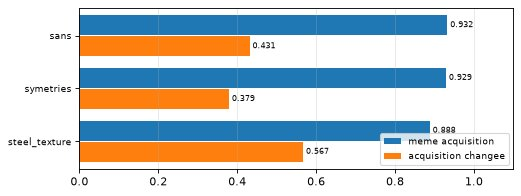

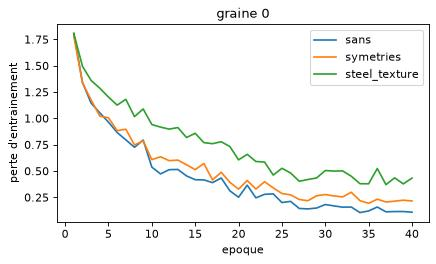

In [19]:
import matplotlib.pyplot as plt  # matplotlib : trace des courbes et des graphiques

# precision moyenne par bras pour chaque test
means = experiment.groupby("arm", sort=False)[["meme acquisition", "acquisition changee"]].mean()
viz.compare_runs(means, ["meme acquisition", "acquisition changee"])  # barres qui comparent les bras sur les deux tests
fig, ax = plt.subplots(figsize=(6, 3.2))  # nouvelle figure de 6 x 3,2 pouces avec un seul graphique (ax)
for r in results:  # pour chaque entrainement
    if r["seed"] == SEEDS[0]:  # seulement ceux de la premiere graine (une courbe par bras)
        # courbe perte d'entrainement / epoque, legendee par le nom du bras
        ax.plot(r["history"]["epoch"], r["history"]["train_loss"], label=r["arm"])
ax.set(xlabel="epoque", ylabel="perte d'entrainement", title=f"graine {SEEDS[0]}")  # titres des axes et du graphique
ax.legend()  # affiche la legende
plt.show()  # affiche la figure

Lecture :
- sur la MEME acquisition, l'augmentation ne gagne rien ici, et le preset complet coute meme
  quelques points : la tache d'entrainement est plus dure (la perte reste plus haute) pour le
  meme nombre d'epoques, et le test ne contient aucune des variations simulees ;
- sur l'acquisition CHANGEE, le modele sans augmentation s'effondre (il a appris l'eclairage
  de ces 150 images avec les defauts) ; le preset garde nettement plus de precision ;
- les symetries seules ne protegent pas d'un changement d'eclairage : chaque operation achete
  une invariance precise, pas une robustesse generale.

D'ou deux regles : choisir les operations d'apres les variations ATTENDUES en production, et
evaluer aussi sur des images de conditions differentes (autre jour, autre reglage) quand on en a,
pas seulement sur un test tire du meme lot que l'entrainement.

## 12. Resultats

In [20]:
viz.metrics_table(  # tableau final des chiffres cles du notebook :
    {  # dictionnaire nom -> valeur
        "operations": N_OPS,  # nombre d'operations du catalogue (sans l'operation maison)
        "presets": len(A.PRESETS),  # nombre de presets
        # presets alignes / nombre de controles (7 presets x 2 taches)
        "presets alignes (detection + segmentation)": f"{int(alignment['ok'].sum())} / {len(alignment)}",
        **{  # ajoute une entree par couple (test, bras), construite ci-dessous :
            # cle "precision <test>, <bras>" -> "moyenne +/- ecart-type", lus dans summary
            f"precision {test}, {arm}": f"{summary.loc[arm, (test, 'mean')]:.3f} +/- {summary.loc[arm, (test, 'std')]:.3f}"
            for test in ("meme acquisition", "acquisition changee")  # pour chacun des deux tests
            for arm in ARMS  # et pour chacun des trois bras
        },
    }
)

,valeur
operations,45
presets,7
presets alignes (detection + segmentation),14 / 14
"precision meme acquisition, sans",0.932 +/- 0.010
"precision meme acquisition, symetries",0.929 +/- 0.013
"precision meme acquisition, steel_texture",0.888 +/- 0.010
"precision acquisition changee, sans",0.431 +/- 0.039
"precision acquisition changee, symetries",0.379 +/- 0.033
"precision acquisition changee, steel_texture",0.567 +/- 0.050


## 13. Adapter a tes donnees

1. Partir d'un preset proche de ses images (`steel_strip`, `steel_texture`, `metal_part`, ou
   `medium`), le REGARDER sur 20 images (`viz.show_augmentations`), retirer ce qui cree des
   images impossibles (`exclude`).
2. Ajouter les variations vues en production et absentes du jeu (autre eclairage :
   `illumination_gradient`, `exposure` ; autre camera : `blur`, `gaussian_noise`, `jpeg`).
3. `check_alignment` sur toute operation ecrite a la main ; `benchmark_ops` si l'entrainement
   attend les donnees.
4. Comparer avec / sans sur la VALIDATION (jamais le test), sur plusieurs graines.

## 14. Passer en production

Dans le YAML d'une recette (classification, detection Faster R-CNN, segmentation,
auto-encodeur d'anomalies) :

```yaml
augment:
  - {name: preset, preset: steel_texture}
  - {name: jpeg, quality: [60, 95], p: 0.2}
```

puis `python recipes/classification/scripts/run.py --config <yaml>`. YOLO, YOLOX et RF-DETR ont
leurs propres augmentations internes (mosaique, HSV...), reglees dans leur section du YAML.
Controle : le YAML d'une recette construit exactement la meme augmentation que le notebook.

In [21]:
from vtb.core.config import load_config  # load_config : lit un fichier YAML et le valide avec un schema
from vtb.tasks.classification.config import ClassificationConfig  # schema (pydantic) de la config d'une recette de classification

# lit le YAML "quick" de la recette de classification
config = load_config("recipes/classification/configs/quick.yaml", ClassificationConfig)
# copie de la config dont la cle augment est remplacee par le preset teste, revalidee par le schema
config = ClassificationConfig.model_validate({**config.model_dump(), "augment": [{"name": "preset", "preset": PRESET}]})
from_yaml = A.build_augmentation(config.augment, "classification")  # augmentation construite depuis la config (comme le fait la recette)
# la meme, ecrite directement comme dans ce notebook
from_notebook = A.build_augmentation([{"name": "preset", "preset": PRESET}], "classification")
torch.manual_seed(SEED)  # meme graine avant chaque appel...
a = from_yaml(x)  # applique la version YAML
torch.manual_seed(SEED)  # ...pour obtenir les memes tirages
b = from_notebook(x)  # applique la version notebook
# torch.equal : True si les deux images sont identiques au pixel pres
print("meme augmentation (YAML de la recette / notebook) :", torch.equal(a, b))
print("augmentation actuelle de quick.yaml :")  # titre de la sortie suivante
# detail de l'augmentation actuellement definie dans quick.yaml
A.describe(load_config("recipes/classification/configs/quick.yaml", ClassificationConfig).augment, "classification")

meme augmentation (YAML de la recette / notebook) : True
augmentation actuelle de quick.yaml :


,step,transform,p,params
0,1,RandomHorizontalFlip,0.5,{}
1,2,RandomVerticalFlip,0.5,{}
2,3,Clamp01,1.0,{}


## Pour aller plus loin

- Augmentation sur GPU par lot : torchvision v2 accepte des tenseurs (N, C, H, W) sur GPU
  (memes parametres pour tout le lot) ; Kornia tire des parametres par image.
- Le notebook 07 (classification) et la recette segmentation montrent l'augmentation dans un
  entrainement complet ; l'article `docs/augmentation.md` resume les choix.